In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Crop_recommendation.csv to Crop_recommendation.csv


In [3]:
import pandas as pd

filename = next(iter(uploaded))
data = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", data.shape)
display(data.head())

Dataset loaded successfully!
Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nNumber of crop categories:", data["label"].nunique())

print("\nCrop distribution:")
print(data["label"].value_counts())

Dataset shape: (2200, 8)

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Number of crop categories: 22

Crop distribution:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [5]:
features = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

X = data[features]
y = data["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Features and target created successfully!")

X shape: (2200, 7)
y shape: (2200,)
Features and target created successfully!


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1760
Testing records: 440


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean CV Accuracy (%)": round(scores.mean() * 100, 2),
        "Standard Deviation (%)": round(scores.std() * 100, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean CV Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(results_df)


,Model,Mean CV Accuracy (%),Standard Deviation (%)
0,Random Forest,99.43,0.48
1,Extra Trees,99.15,0.36
2,Gradient Boosting,98.69,0.34
3,SVM,97.90,1.03
4,KNN,96.53,1.21


In [9]:

best_model_name = "Random Forest"
best_model = models[best_model_name]

best_model.fit(X_train, y_train)

print("Selected Model:", best_model_name)
print("Cross-validation Accuracy: 99.43%")
print("Model training completed successfully!")


Selected Model: Random Forest
Cross-validation Accuracy: 99.43%
Model training completed successfully!


In [10]:

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Model:", best_model_name)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1 Score: {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


MODEL PERFORMANCE
-------------------------
Model: Random Forest
Test Accuracy: 99.55%
Precision: 99.57%
Recall: 99.55%
F1 Score: 99.55%

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00     

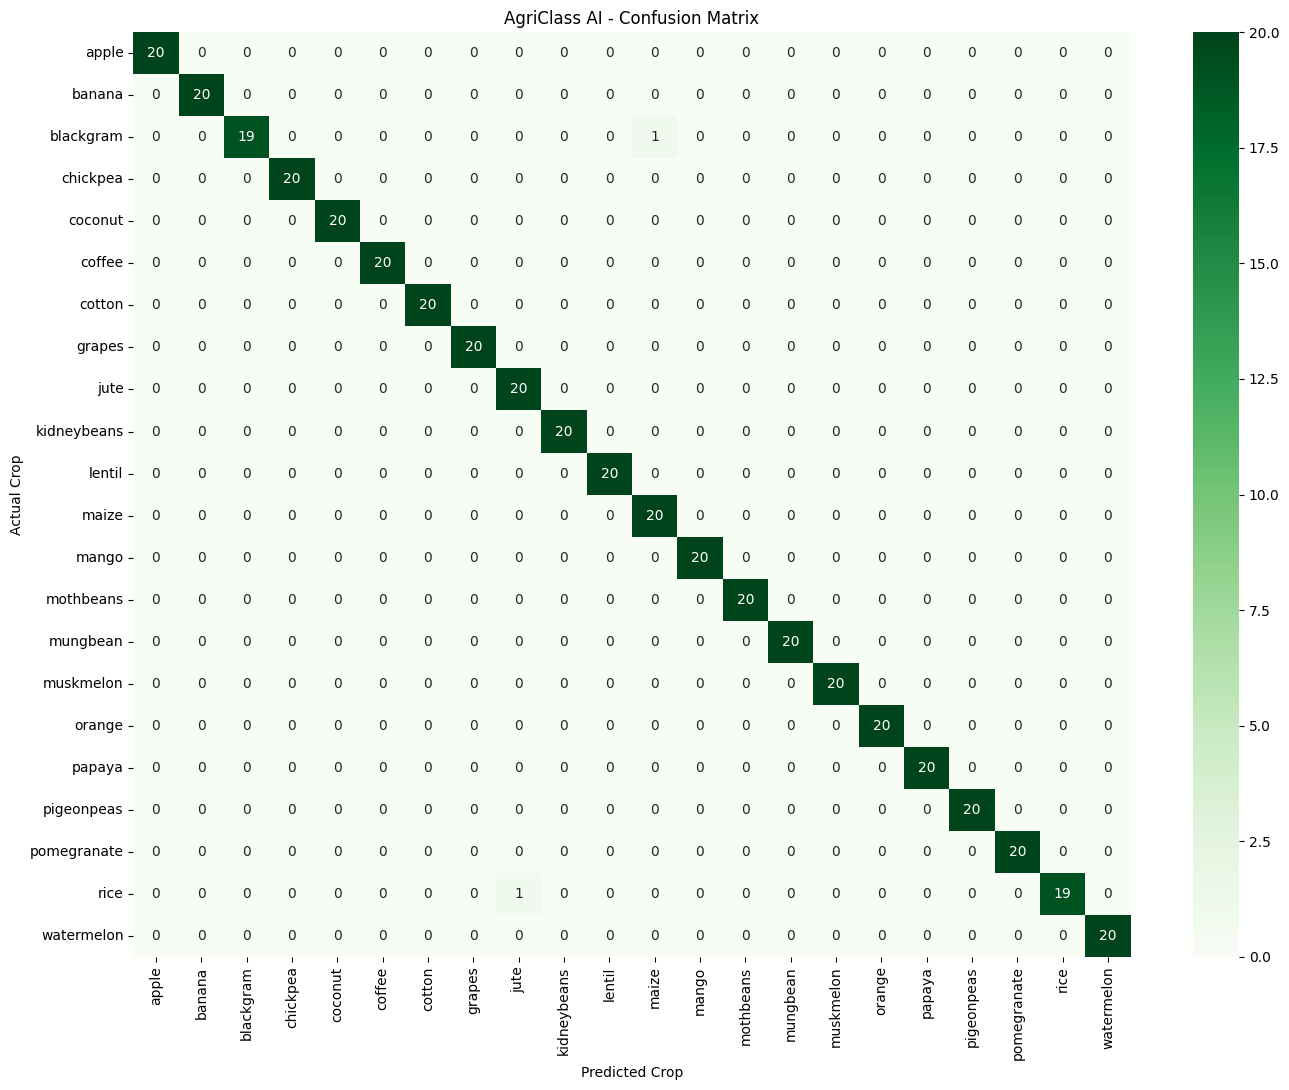

In [11]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("AgriClass AI - Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


,Feature,Importance
6,rainfall,0.2196
4,humidity,0.2171
2,K,0.1808
1,P,0.1513
0,N,0.1034
3,temperature,0.0755
5,ph,0.0523


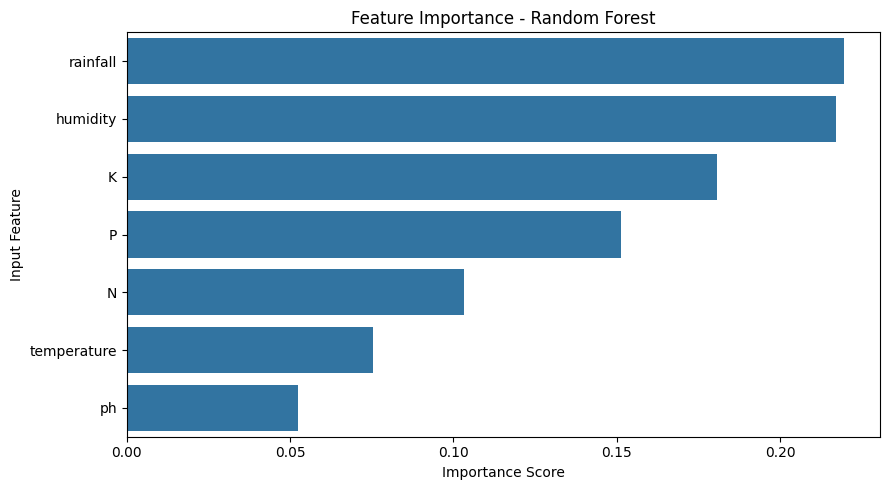

In [12]:

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.tight_layout()
plt.show()


In [13]:

sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25.0,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 100.0
}])[features]

prediction = best_model.predict(sample)[0]

print("🌱 RECOMMENDED CROP:", prediction.upper())

probabilities = best_model.predict_proba(sample)[0]

top_indices = np.argsort(probabilities)[::-1][:5]

top_five = pd.DataFrame({
    "Crop": best_model.classes_[top_indices],
    "Model Score (%)": probabilities[top_indices] * 100
})

display(top_five.round(2))


🌱 RECOMMENDED CROP: JUTE


,Crop,Model Score (%)
0,jute,42.5
1,banana,16.0
2,papaya,12.0
3,cotton,6.5
4,maize,6.5


In [14]:

model_artifact = {
    "model": best_model,
    "features": features,
    "model_name": best_model_name,
    "test_accuracy": accuracy
}

joblib.dump(model_artifact, "/content/crop_model.pkl")

print("Model saved successfully!")
print("File: crop_model.pkl")


Model saved successfully!
File: crop_model.pkl
